# Model Training: COVID vs Non-COVID

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc,
                             accuracy_score, classification_report)

SEED = 42
np.random.seed(SEED)

## 1) Import the final dataset

In [3]:
df = pd.read_csv("Final_Dataset_AIBD.csv", low_memory=False)
print(df.shape)
df.head()

(185, 17726)


,Unnamed: 0.1,Unnamed: 0,Age,Gender,ICU,RUNDC3A,DEPDC1,BICDL1,ATP5PB,COTL1,...,CCR1,DMTN,CAVIN2,IZUMO4,SEPTIN10,ZCWPW1,DENND4C,TBX3,SCD5,H2AP
0,0,C1,39,male,no,0.41,0.29,3.50,83.13,793.95,...,464.73,24.29,55.98,1.79,1.93,2.26,10.80,0.00,0.89,0.0
1,1,C2,63,male,no,0.38,0.93,4.37,94.44,990.27,...,177.66,35.44,99.14,1.74,1.69,2.61,6.19,0.00,1.13,0.0
2,2,C3,33,male,no,0.39,0.10,2.24,41.24,719.21,...,393.77,6.81,12.31,1.86,0.38,6.12,3.59,0.00,0.62,0.0
3,3,C4,49,male,no,0.56,0.19,7.87,123.22,804.48,...,256.23,24.50,122.51,3.43,1.82,5.01,9.48,0.01,1.59,0.0
4,4,C5,49,male,no,0.45,0.44,1.92,72.72,505.98,...,482.63,15.10,44.62,0.51,0.21,3.15,4.39,0.00,0.65,0.0


## 2-4) Select median significant genes, stratified 80-20 split, normalize
Label: sample IDs starting with `C` = COVID (1), `NC` = non-COVID (0). Genes = union of the elevation and suppression lists in `median_significant_genes.json`.
The scaler is fit on the training set only and then applied to the test set, to avoid data leakage.

In [4]:
with open("median_significant_genes.json") as f:
    sig = json.load(f)
genes = [g for g in dict.fromkeys(sum(sig.values(), [])) if g in df.columns]
print("Number of median significant genes used:", len(genes))

y = (~df["Unnamed: 0"].astype(str).str.startswith("NC")).astype(int)   # 1 = COVID, 0 = non-COVID
X = df[genes]
print(y.value_counts().rename({1: "COVID", 0: "Non-COVID"}))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("Train:", X_train.shape, "Test:", X_test.shape)

Number of median significant genes used: 12720
Unnamed: 0
COVID        100
Non-COVID     85
Name: count, dtype: int64
Train: (148, 12720) Test: (37, 12720)


## 5) Models

In [5]:
def evaluate(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)
    print(f"{name} - accuracy: {accuracy_score(y_test, y_pred):.3f}")
    print(classification_report(y_test, y_pred, target_names=["Non-COVID", "COVID"]))
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Non-COVID", "COVID"], cmap="Blues", ax=ax[0])
    ax[0].set_title(f"{name} - Confusion Matrix")
    ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    ax[1].plot([0, 1], [0, 1], "k--")
    ax[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=f"{name} - ROC Curve")
    ax[1].legend(loc="lower right")
    plt.tight_layout(); plt.show()
    return model

### Logistic Regression

Logistic Regression - accuracy: 0.919
              precision    recall  f1-score   support

   Non-COVID       0.85      1.00      0.92        17
       COVID       1.00      0.85      0.92        20

    accuracy                           0.92        37
   macro avg       0.93      0.93      0.92        37
weighted avg       0.93      0.92      0.92        37



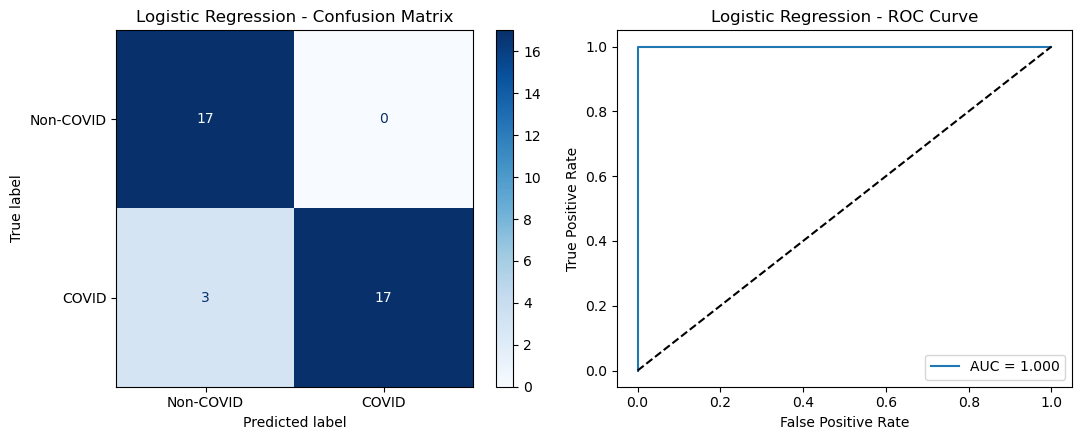

In [6]:
lr_model = evaluate(LogisticRegression(max_iter=5000, random_state=SEED), "Logistic Regression")

### SVM

SVM - accuracy: 0.865
              precision    recall  f1-score   support

   Non-COVID       0.83      0.88      0.86        17
       COVID       0.89      0.85      0.87        20

    accuracy                           0.86        37
   macro avg       0.86      0.87      0.86        37
weighted avg       0.87      0.86      0.87        37



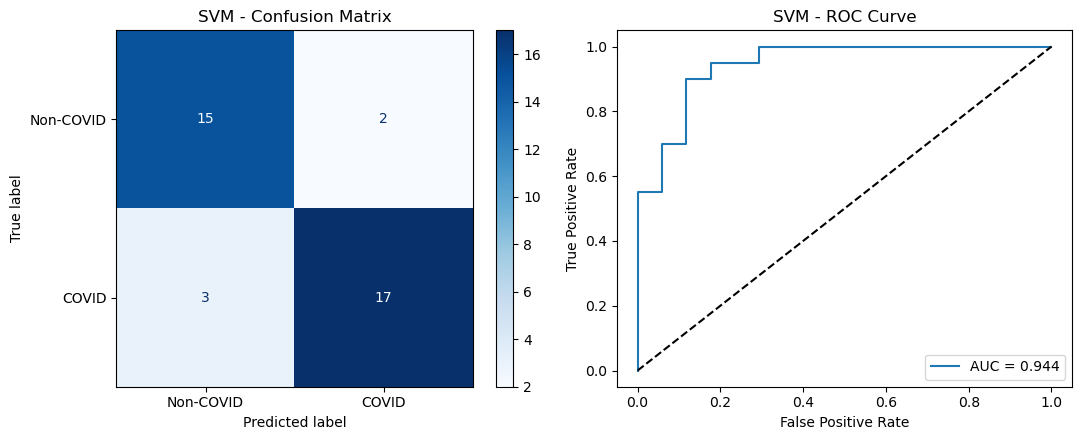

In [7]:
svm_model = evaluate(SVC(kernel="rbf", probability=True, random_state=SEED), "SVM")

### Random Forest

Random Forest - accuracy: 0.946
              precision    recall  f1-score   support

   Non-COVID       0.89      1.00      0.94        17
       COVID       1.00      0.90      0.95        20

    accuracy                           0.95        37
   macro avg       0.95      0.95      0.95        37
weighted avg       0.95      0.95      0.95        37



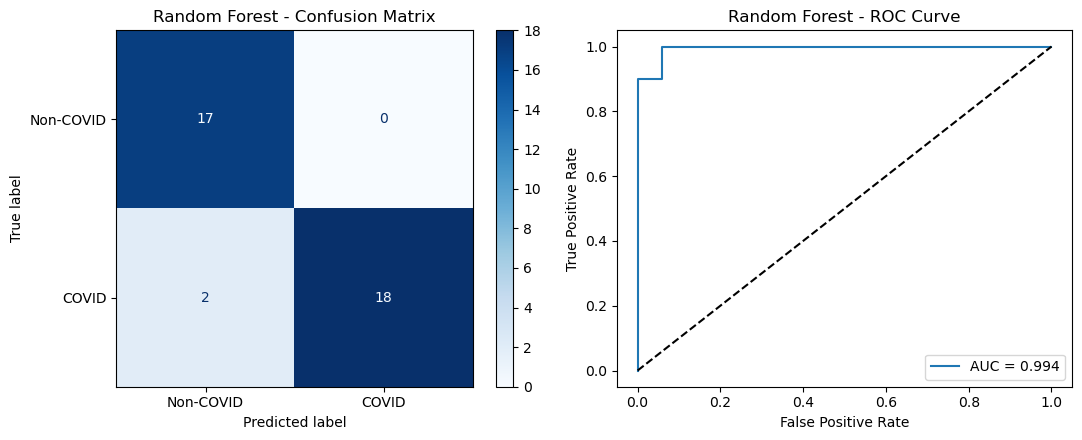

In [8]:
rf_model = evaluate(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), "Random Forest")

## Feature importance
Importance per model, each normalized to sum to 1 (relative importance). SVM is skipped (the RBF kernel has no coefficients, and permutation importance was too slow):
- Logistic Regression: absolute coefficient (features are standardized, so coefficients are comparable)
- Random Forest: impurity-based `feature_importances_`

In [9]:
def normalize(v):
    v = np.clip(np.asarray(v, dtype=float), 0, None)
    return v / v.sum() if v.sum() > 0 else v

importances = pd.DataFrame({
    "Logistic Regression": normalize(np.abs(lr_model.coef_[0])),
    "Random Forest": normalize(rf_model.feature_importances_),
}, index=genes)
importances.sort_values("Random Forest", ascending=False).head(10)

,Logistic Regression,Random Forest
MKI67,0.000197,0.016230
BUB1B,0.000156,0.013471
RNA5S15,0.000575,0.010863
RNA5S5,0.000575,0.010555
SHCBP1,0.000088,0.010206
ASPM,0.000207,0.009968
PBK,0.000174,0.009091
RNA5S4,0.000575,0.008602
PARPBP,0.000184,0.008046
RNA5S7,0.000575,0.007840


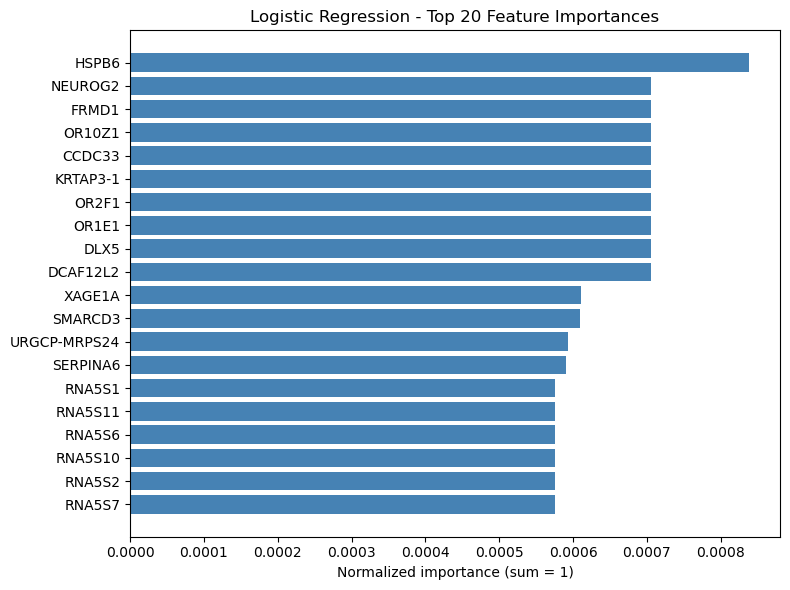

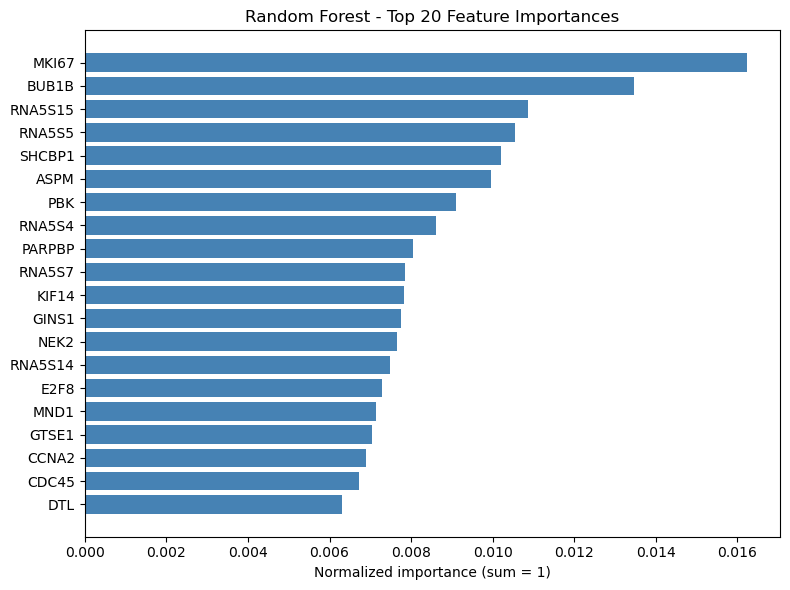

In [10]:
TOP_N = 20
for model_name in importances.columns:
    top = importances[model_name].nlargest(TOP_N).sort_values()
    plt.figure(figsize=(8, 6))
    plt.barh(top.index, top.values, color="steelblue")
    plt.xlabel("Normalized importance (sum = 1)")
    plt.title(f"{model_name} - Top {TOP_N} Feature Importances")
    plt.tight_layout(); plt.show()

### Logistic Regression vs Random Forest importance (all genes)

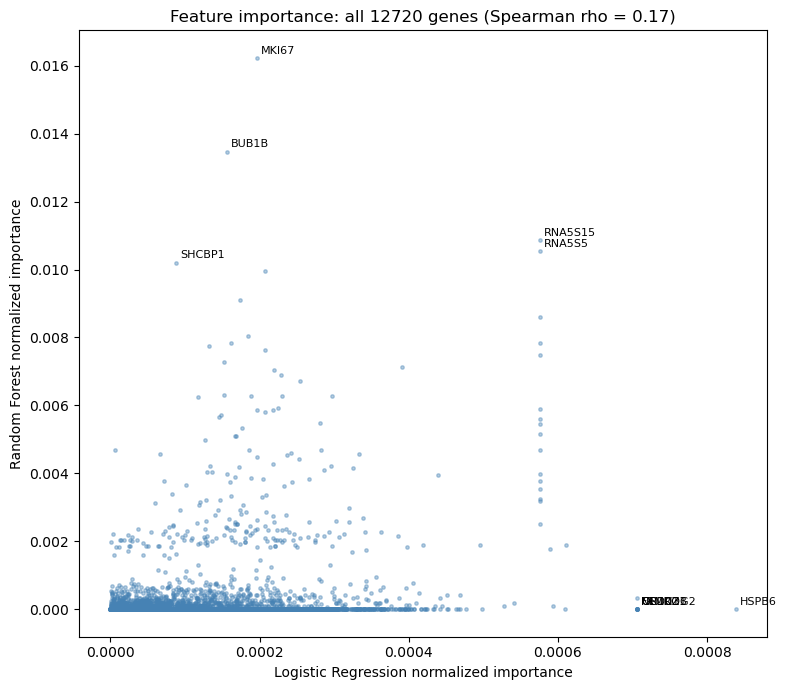

In [11]:
from scipy.stats import spearmanr

x = importances["Logistic Regression"]
y_ = importances["Random Forest"]
rho, _ = spearmanr(x, y_)

plt.figure(figsize=(8, 7))
plt.scatter(x, y_, s=6, alpha=0.4, color="steelblue")
for gene in set(x.nlargest(5).index) | set(y_.nlargest(5).index):   # label the top genes of each model
    plt.annotate(gene, (x[gene], y_[gene]), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.xlabel("Logistic Regression normalized importance")
plt.ylabel("Random Forest normalized importance")
plt.title(f"Feature importance: all {len(genes)} genes (Spearman rho = {rho:.2f})")
plt.tight_layout(); plt.show()

In [12]:
import os
import joblib

os.makedirs("saved_models_1", exist_ok=True)
joblib.dump(lr_model, "saved_models_1/logistic_regression.joblib")
joblib.dump(svm_model, "saved_models_1/svm.joblib")
joblib.dump(rf_model, "saved_models_1/random_forest.joblib")
joblib.dump(scaler, "saved_models_1/scaler.joblib")          # needed to preprocess new data
with open("saved_models_1/genes.json", "w") as f:             # feature order the models expect
    json.dump(genes, f)
print("Saved:", os.listdir("saved_models_1"))

Saved: ['genes.json', 'logistic_regression.joblib', 'random_forest.joblib', 'scaler.joblib', 'svm.joblib']
